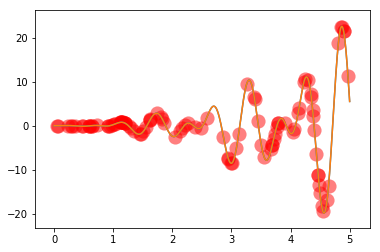

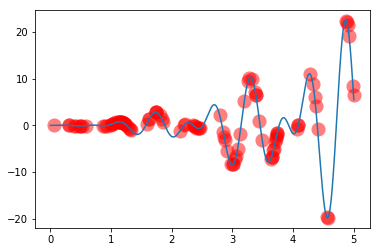

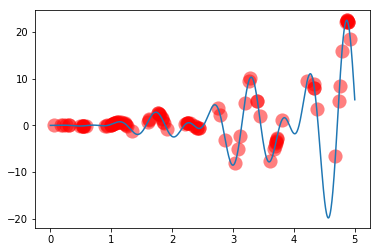

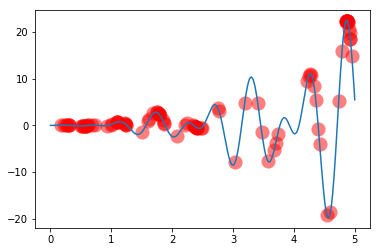

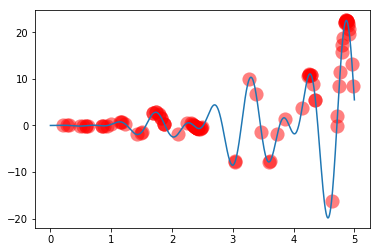

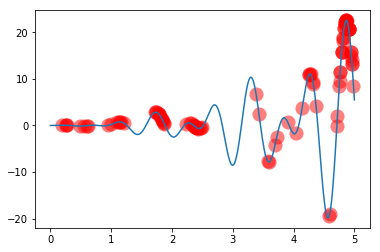

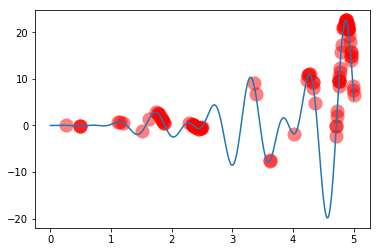

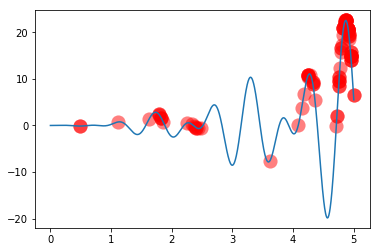

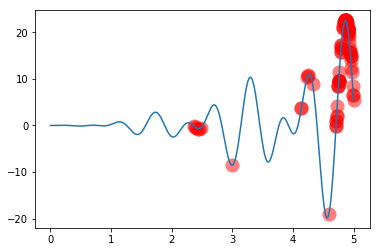

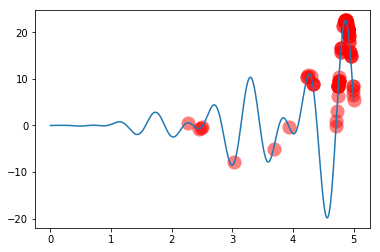

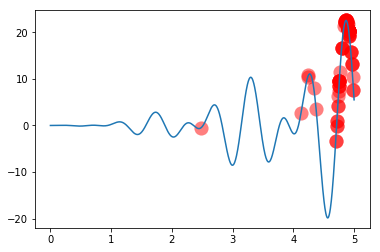

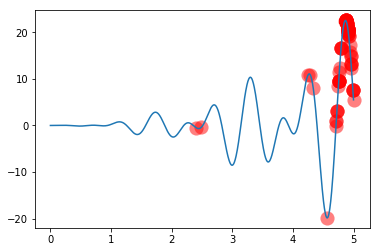

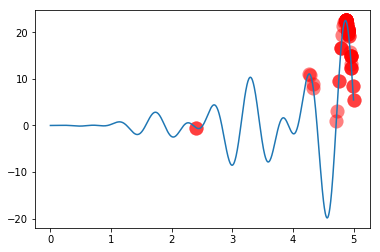

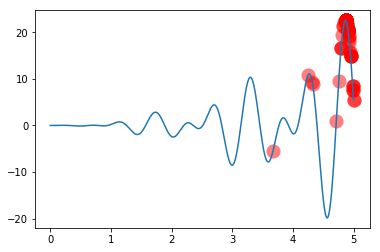

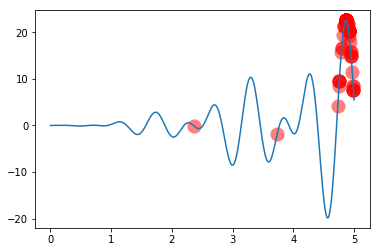

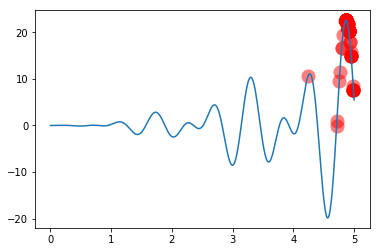

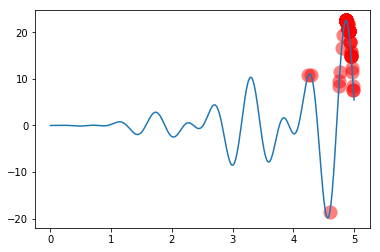

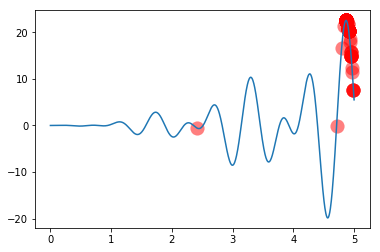

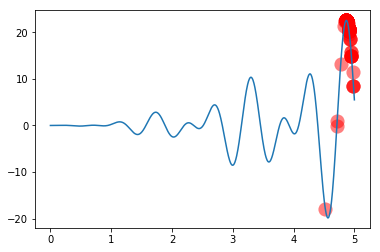

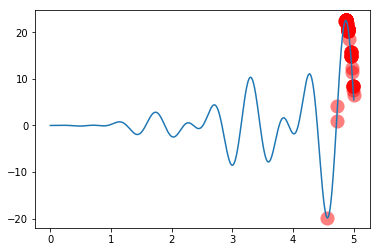

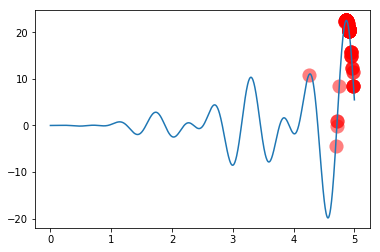

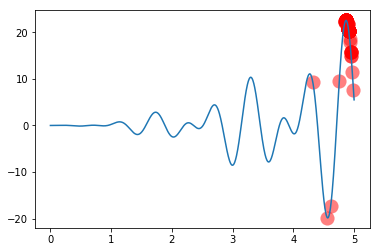

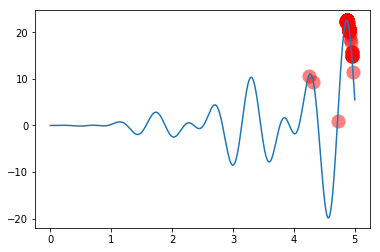

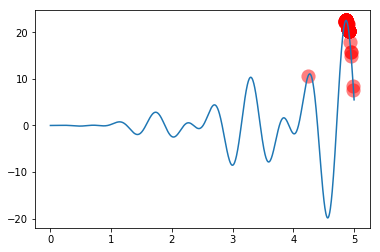

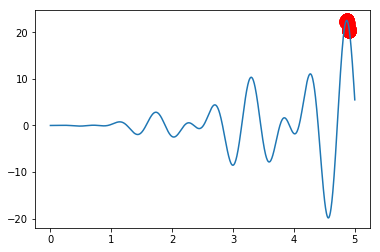

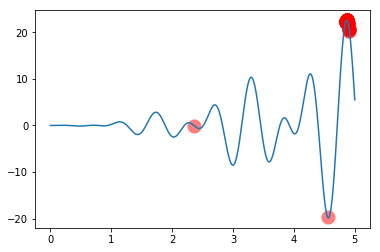

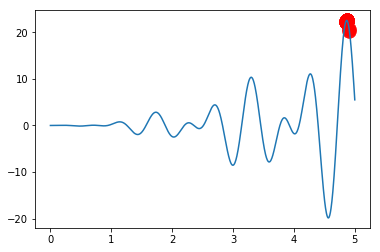

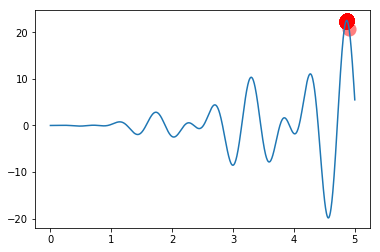

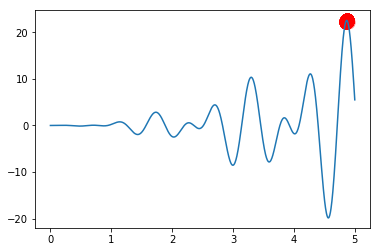

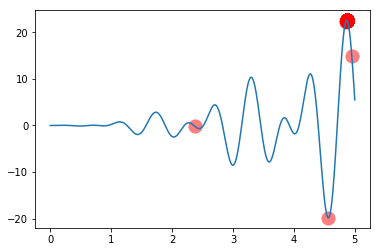

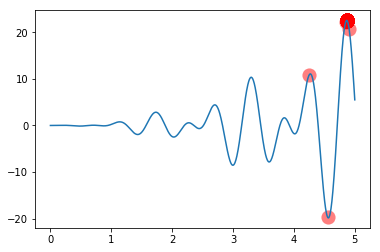

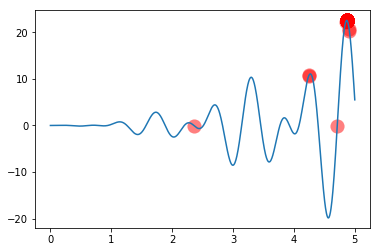

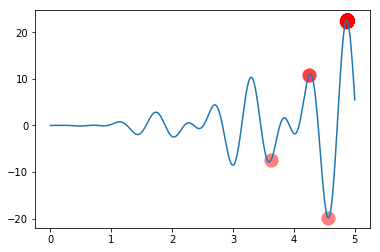

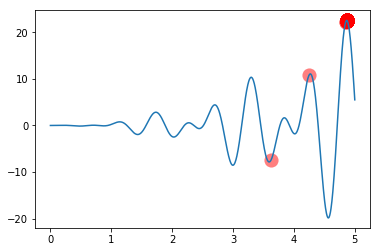

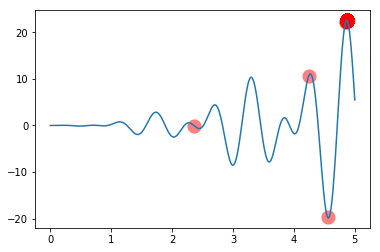

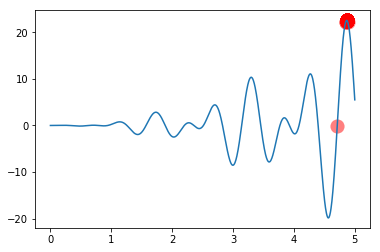

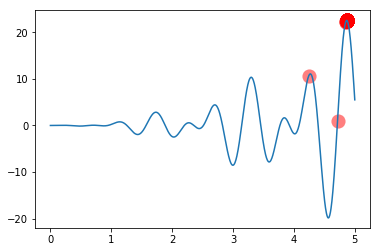

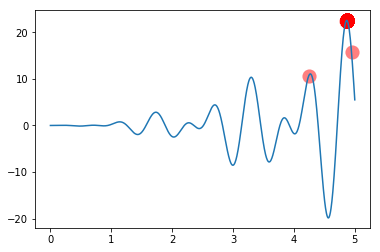

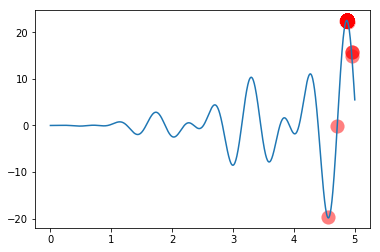

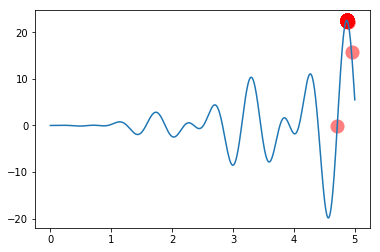

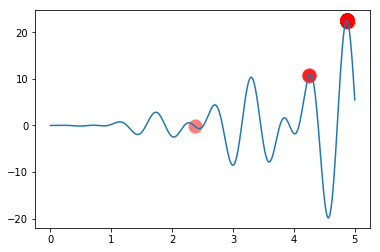

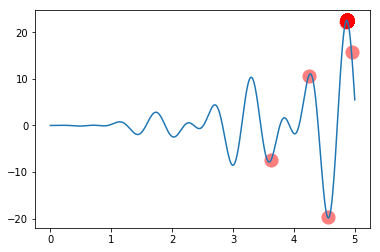

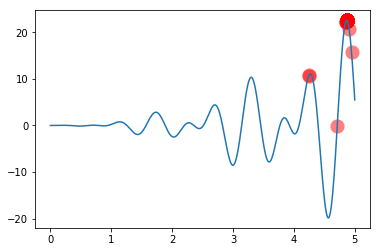

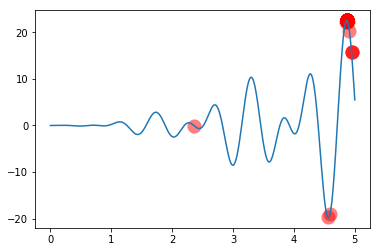

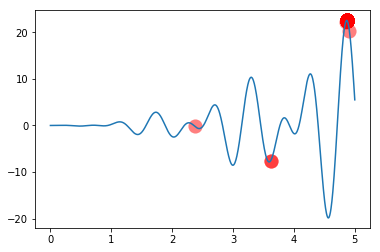

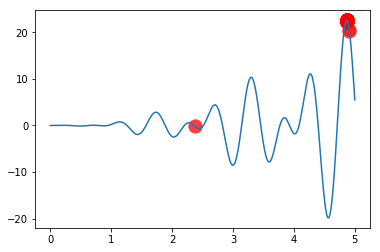

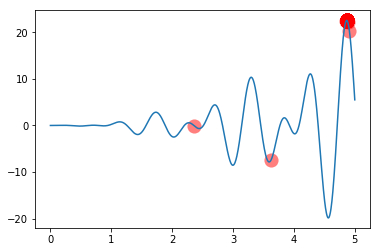

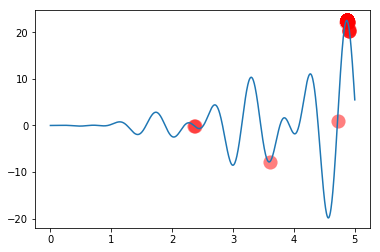

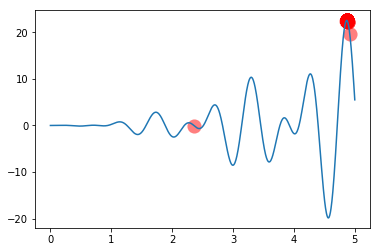

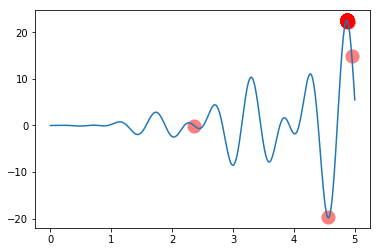

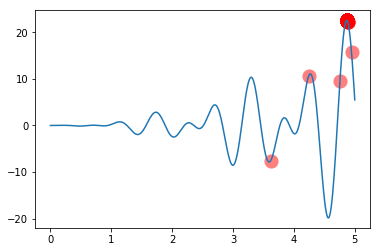

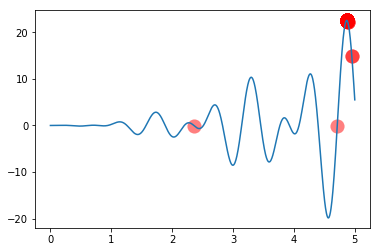

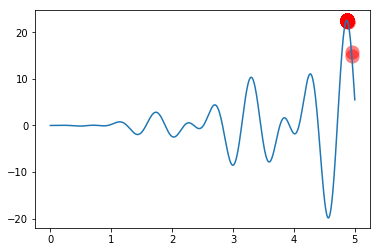

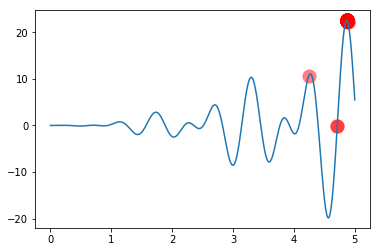

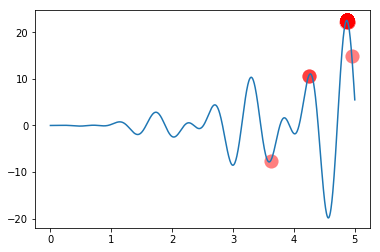

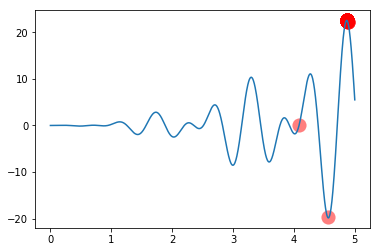

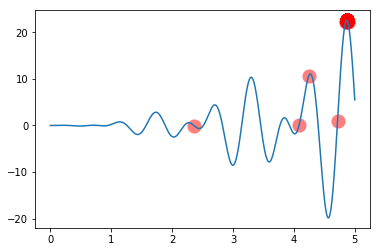

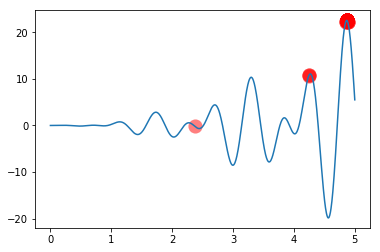

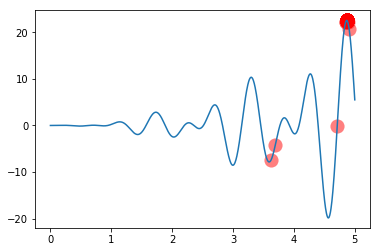

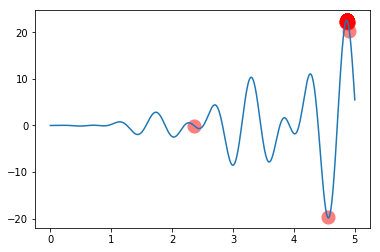

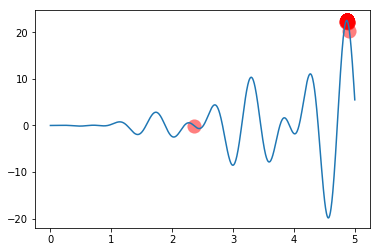

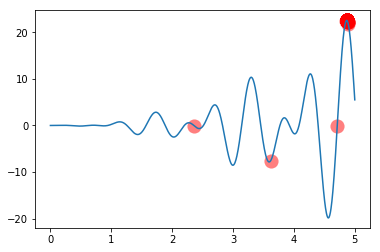

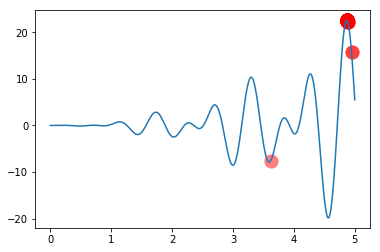

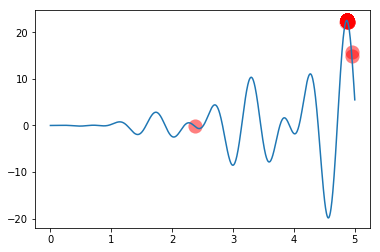

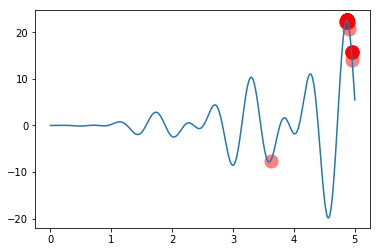

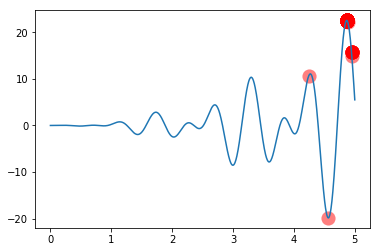

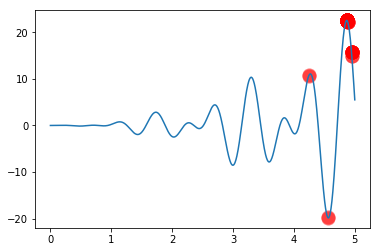

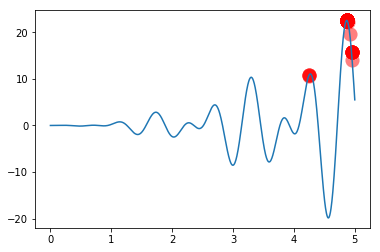

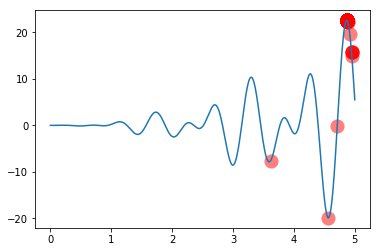

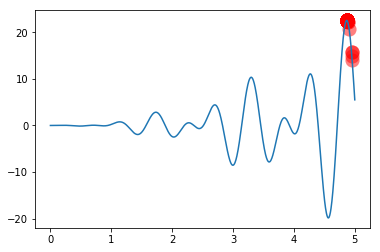

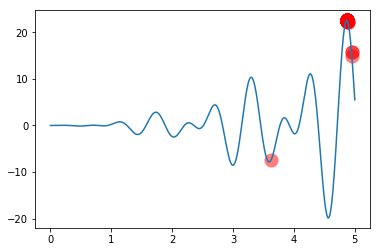

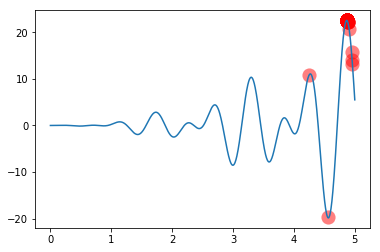

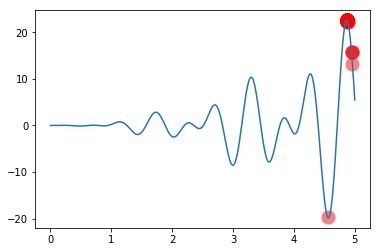

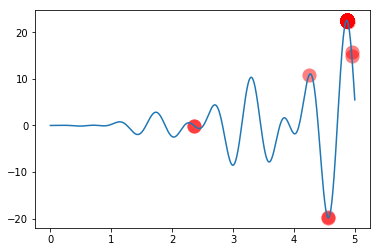

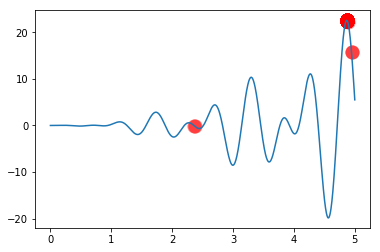

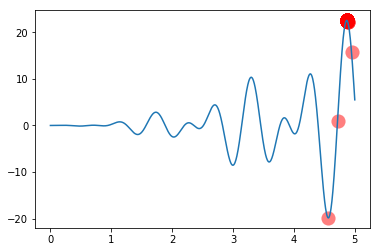

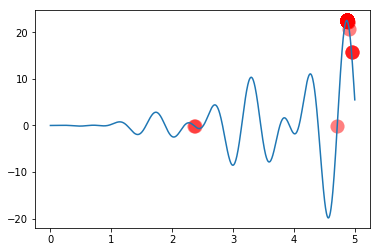

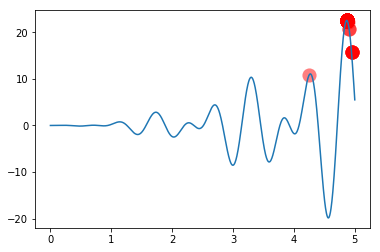

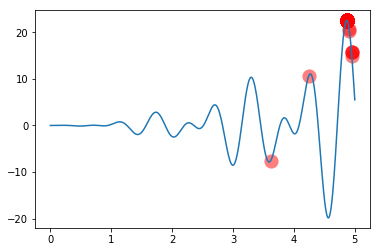

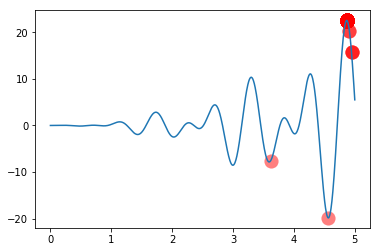

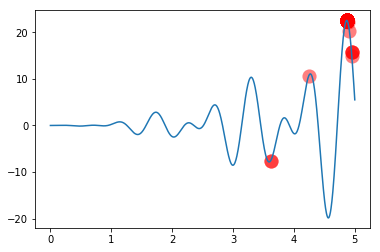

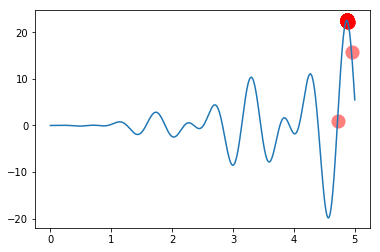

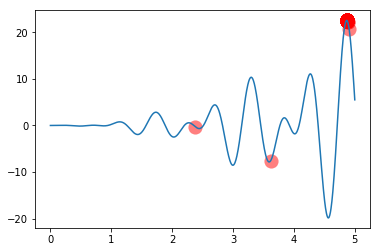

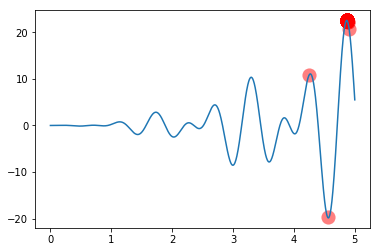

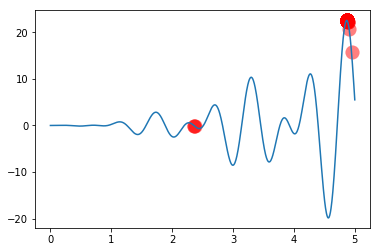

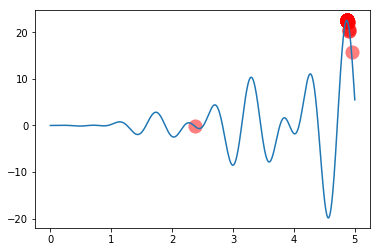

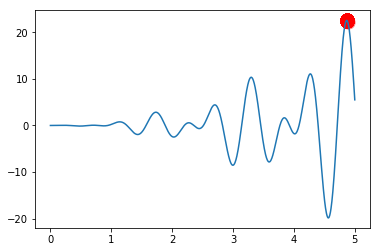

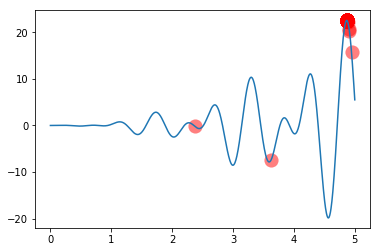

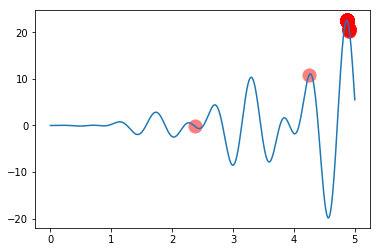

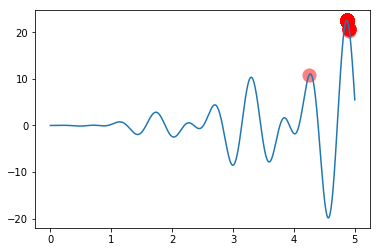

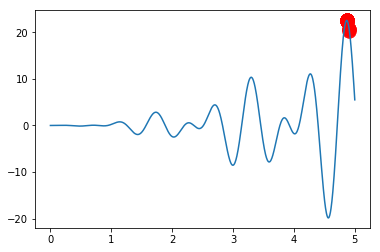

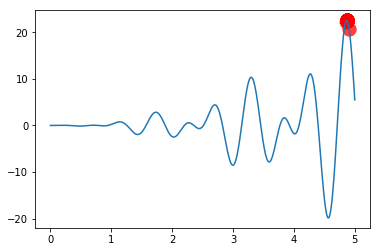

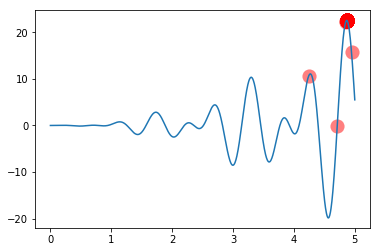

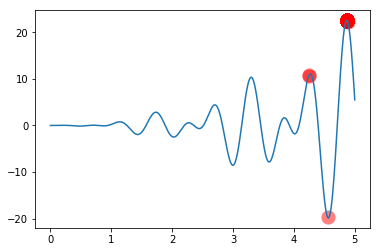

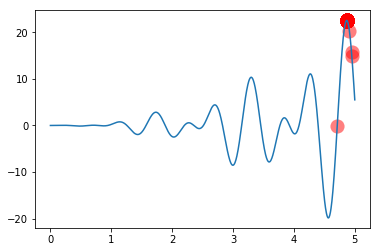

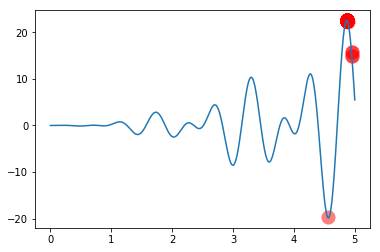

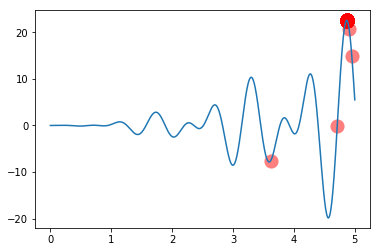

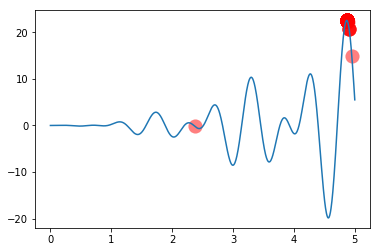

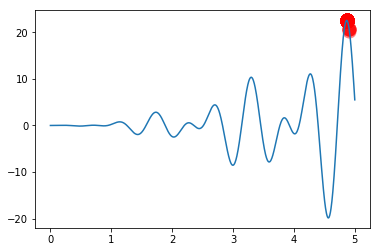

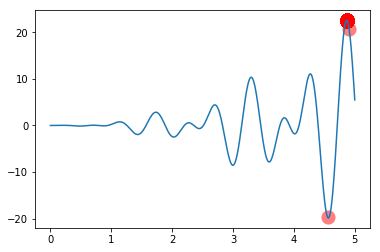

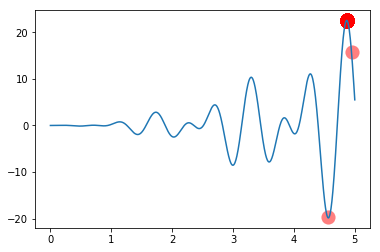

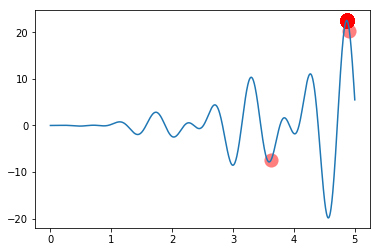

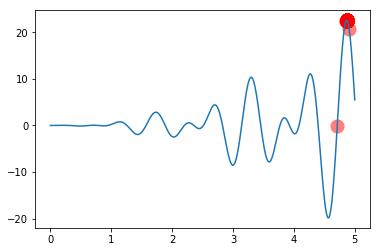

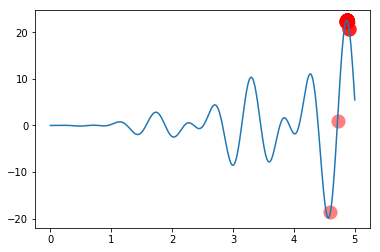

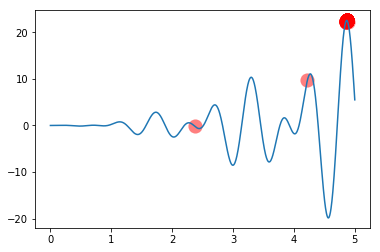

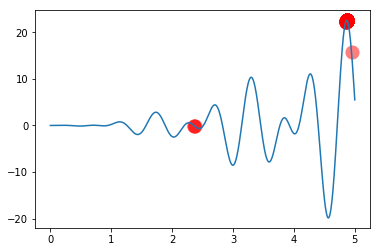

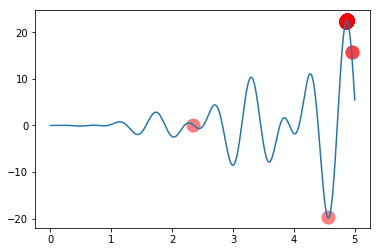

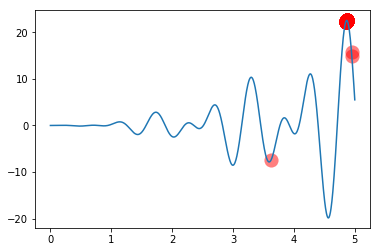

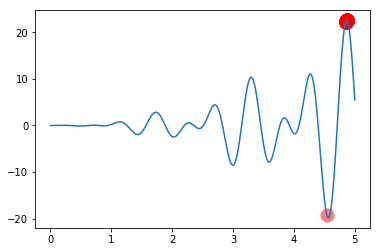

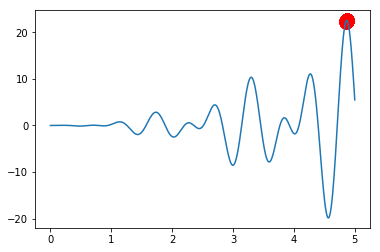

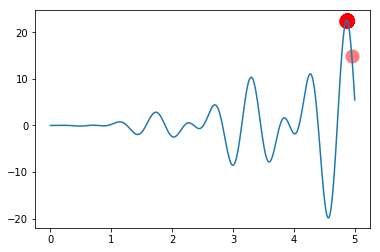

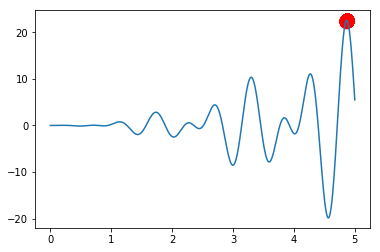

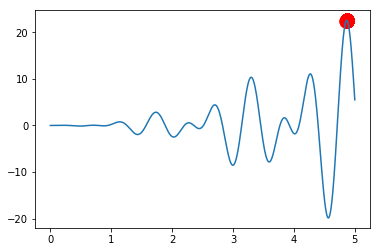

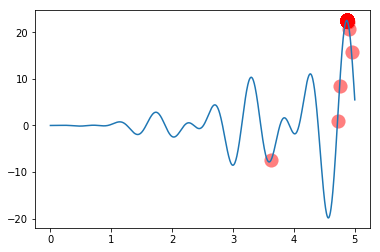

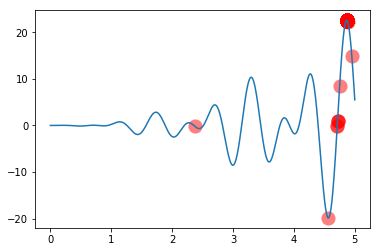

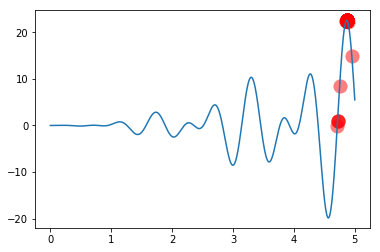

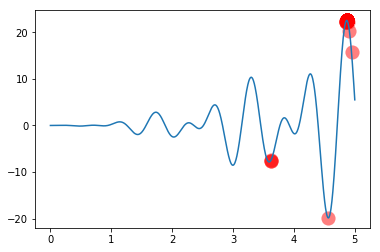

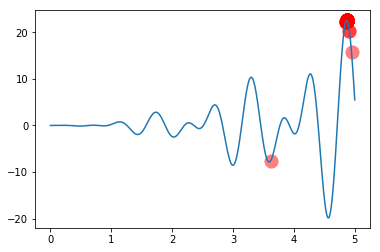

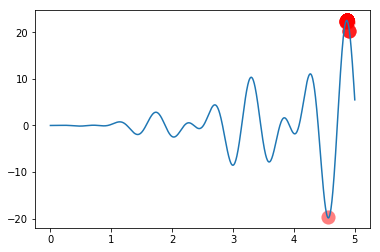

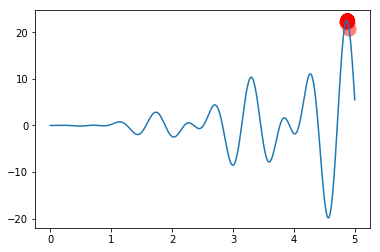

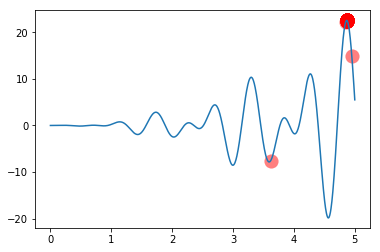

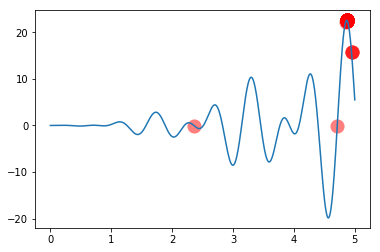

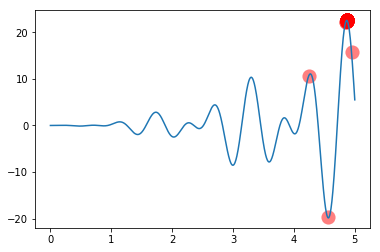

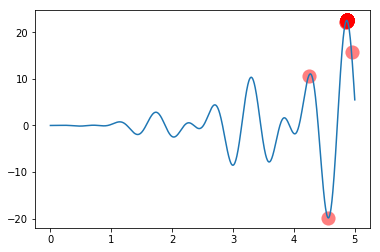

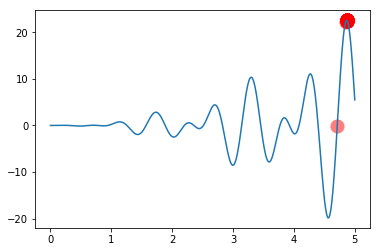

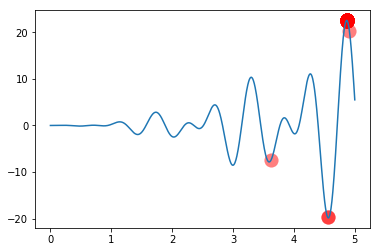

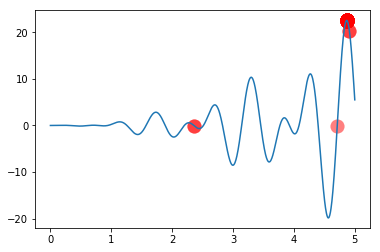

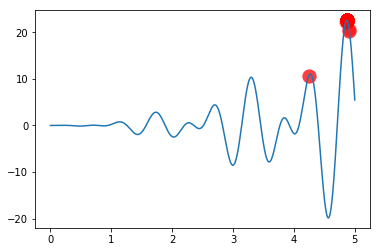

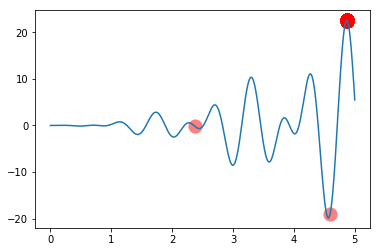

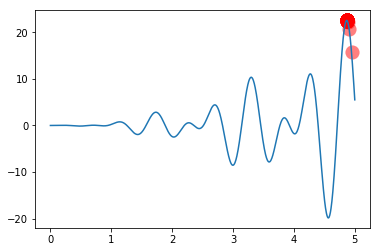

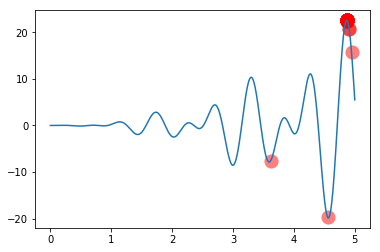

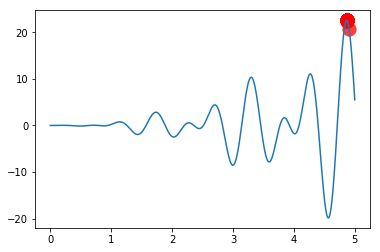

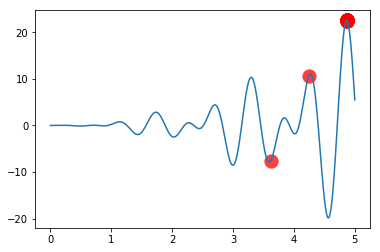

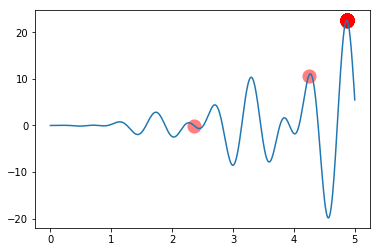

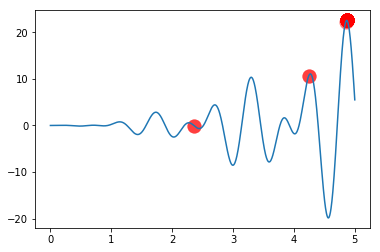

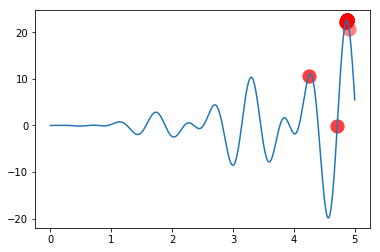

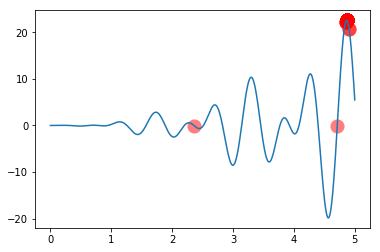

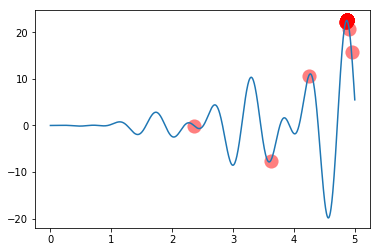

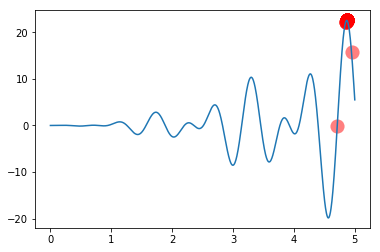

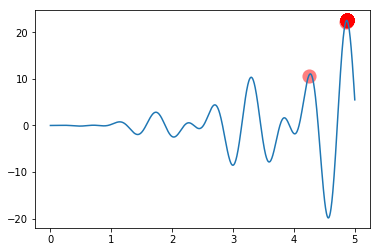

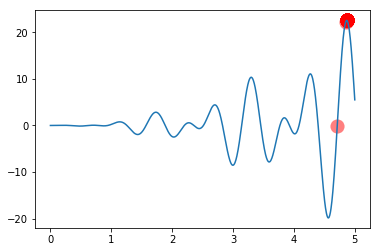

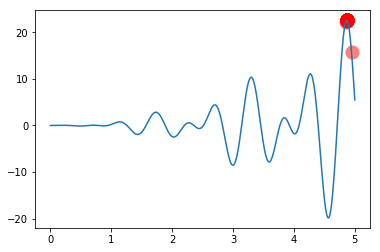

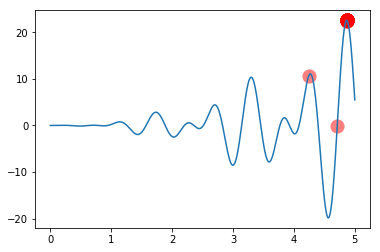

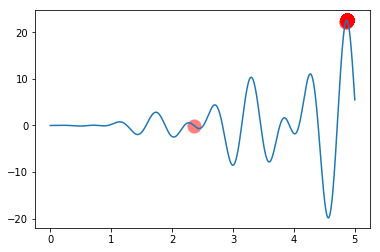

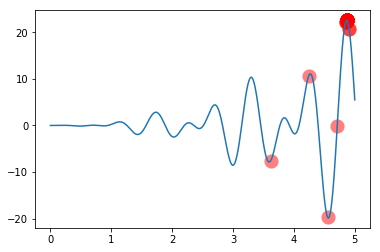

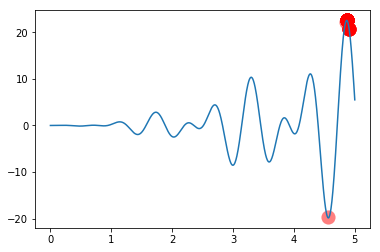

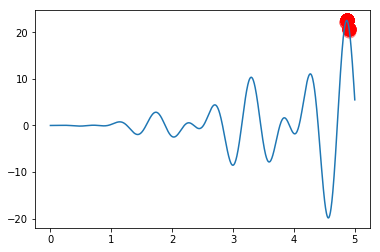

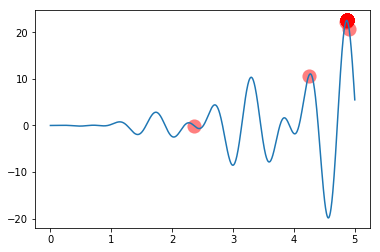

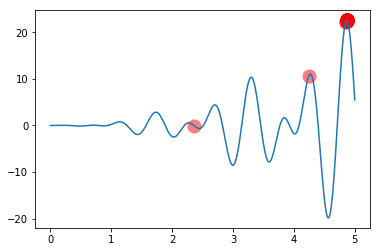

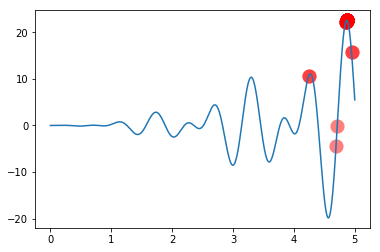

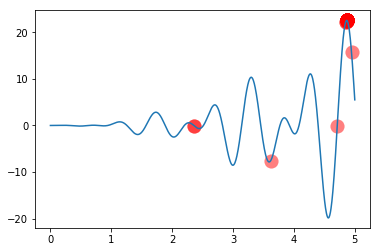

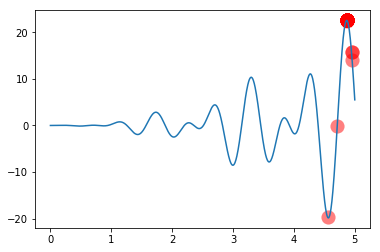

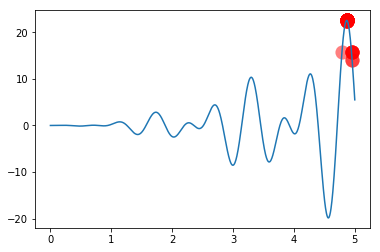

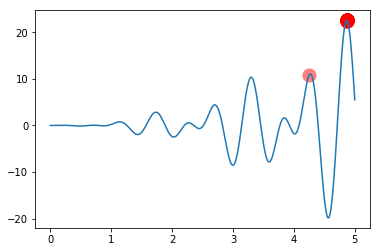

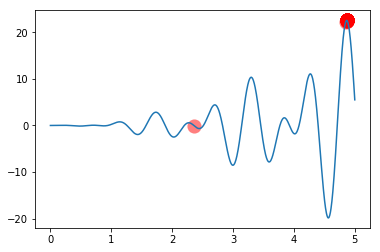

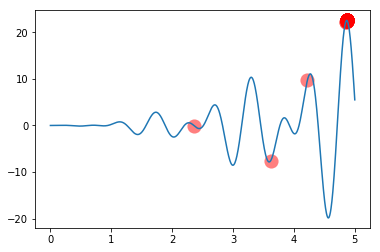

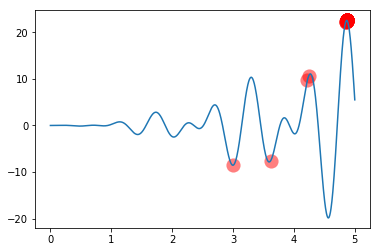

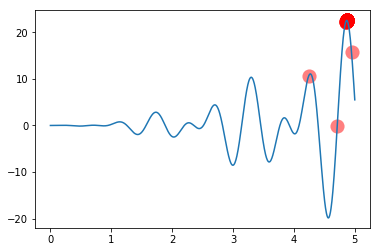

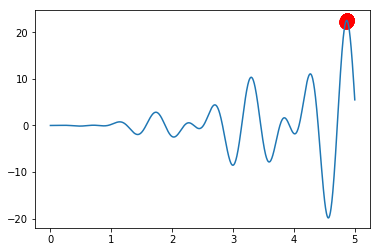

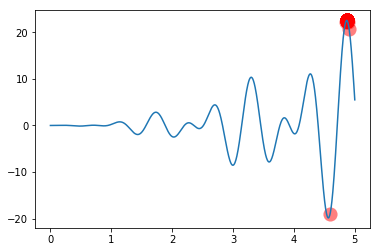

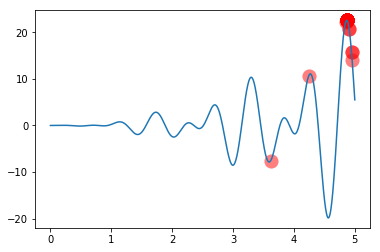

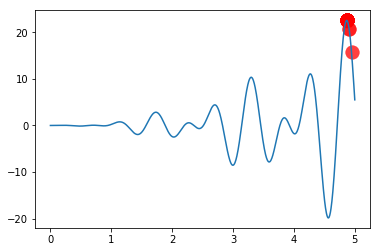

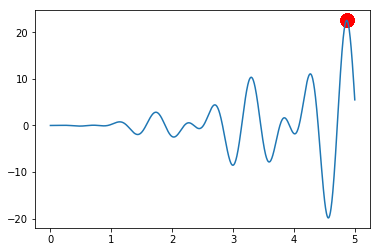

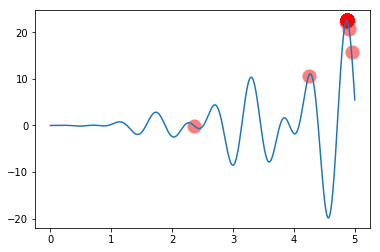

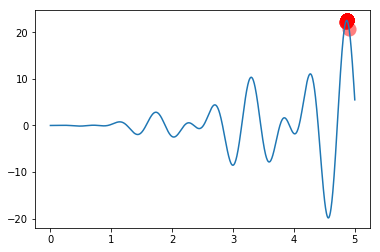

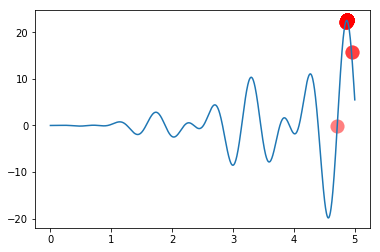

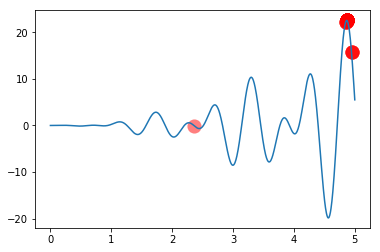

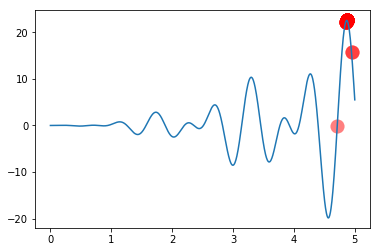

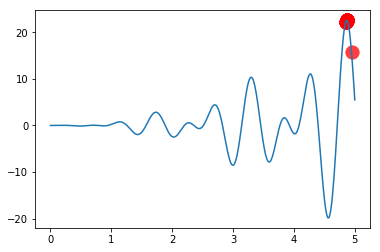

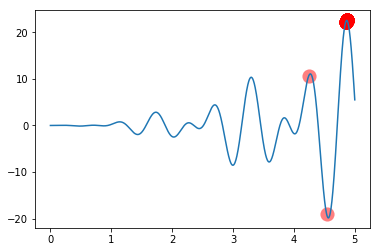

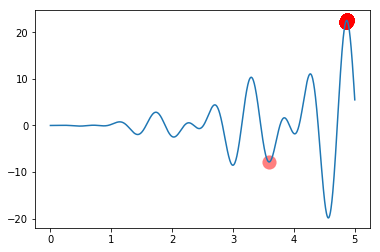

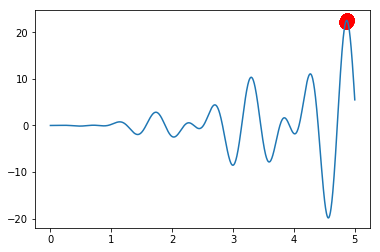

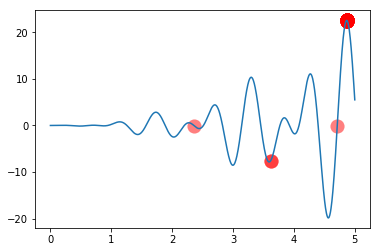

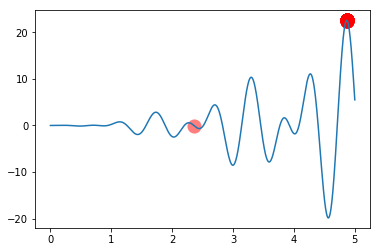

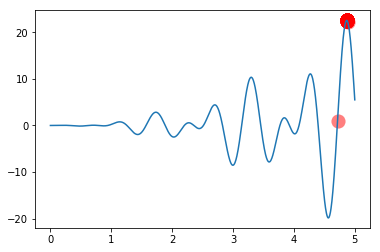

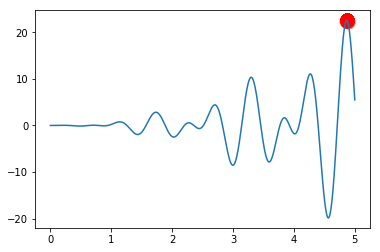

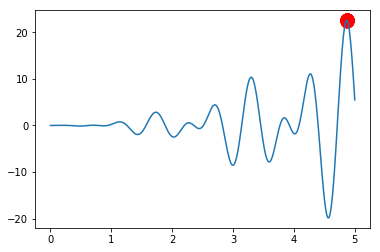

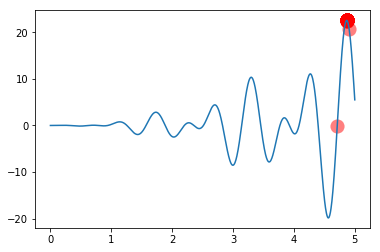

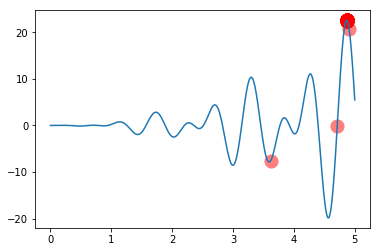

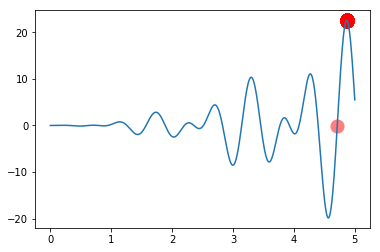

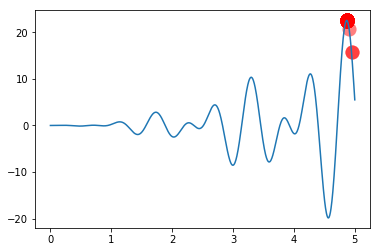

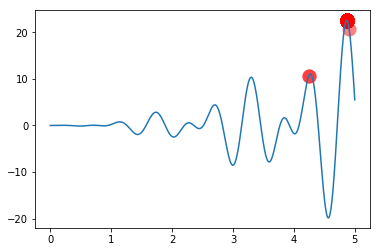

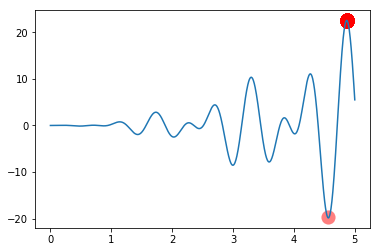

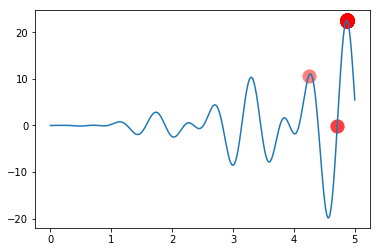

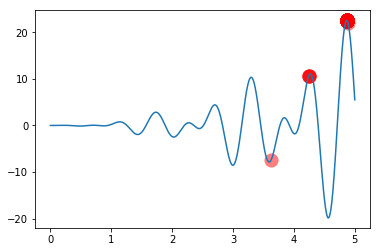

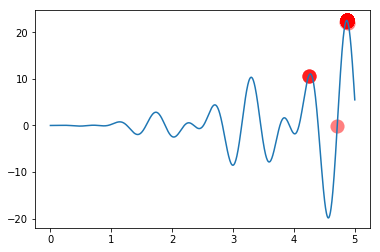

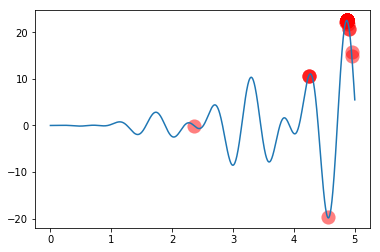

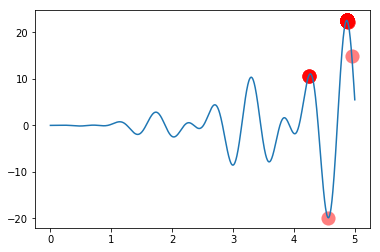

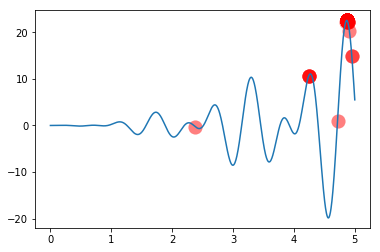

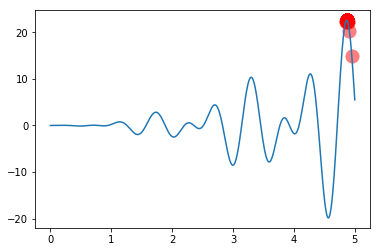

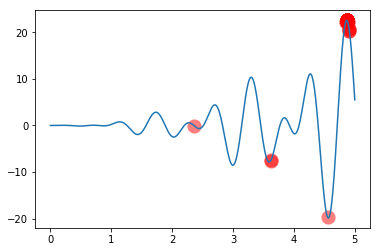

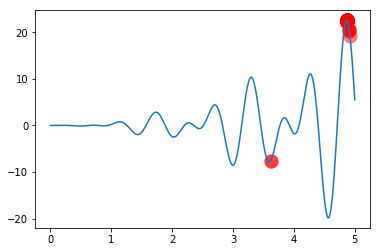

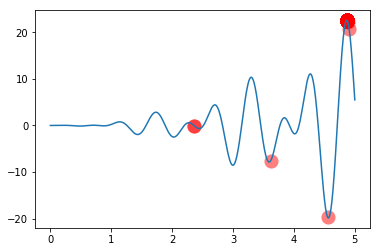

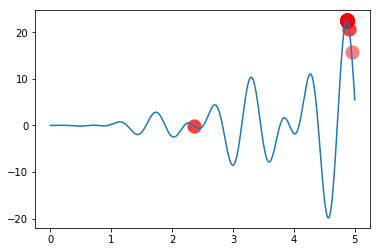

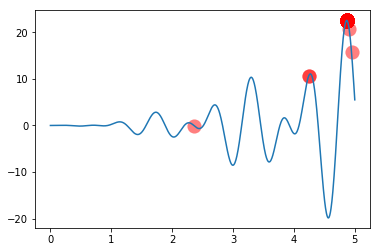

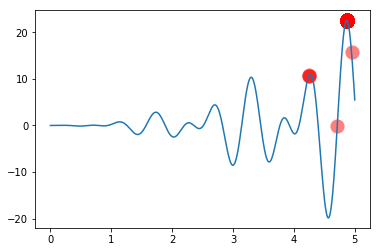

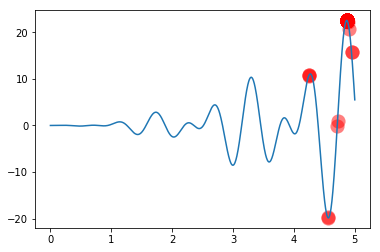

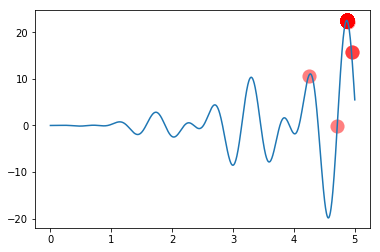

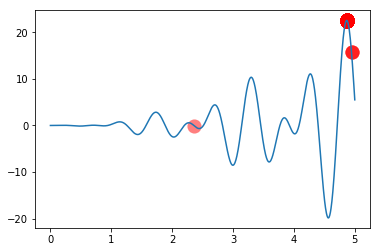

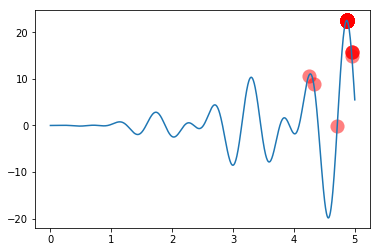

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

txCrossing    = 0.8          # Taxa de Crossover
txMutation    = 0.003        # Taxa de Mutation
epochs        = 200          # Quantidade de Épocas  
lenDNA        = 10           # Tamanho do DNA, implica na quantidade de casas decimais
lenPopulation = 100          # Tamanho da População Inicial
limits        = [0,5]        # Define os limites superior e inferior da função a ser otimizada

### Função a ser maximizada #########################################
                                                                  ###
def F(x): return np.sin(10*x)*x * np.cos(2*x)*x                   ###
                                                                  ###    
#####################################################################    

### Extrai o valor decimal do cromossomo e normaliza entre limits[] #
                                                                  ###
def extractPhenotype(chrm):                                       ###
    return chrm.dot(2 ** np.arange(lenDNA)[::-1]) / float(        ###
        2**lenDNA-1) * limits[1]                                  ###
                                                                  ###
#####################################################################

### Função de avaliação : cada valor e sómado a 0.001 para não    ###
### zerar e lhe é subtraido o menor valor da lista.               ### 
### P. ex. o pior valor recebe fitness igual a zero               ###
                                                                  ###
def get_fitness(indv): return indv + 1e-3 - np.min(indv)          ###
                                                                  ###
#####################################################################    

### Operador genético de Seleção ####################################
                                                                  ###
def select(indv, fitness):                                        ###
    idx = np.random.choice(np.arange(lenPopulation),              ###
                           size=lenPopulation,                    ###
                           replace=True,                          ###
                           p=fitness/fitness.sum())               ###
    return indv[idx]                                              ###
                                                                  ###
#####################################################################

### Operador genético de Crossover ##################################
                                                                  ###
def cross(pai, indvs):                                            ###
    if np.random.rand() < txCrossing:                             ###
        i_ = np.random.randint(0, lenPopulation, size=1)          ###                   
        cross_points = np.random.randint(                         ###
            0, 2, size=lenDNA).astype(np.bool)                    ###
        pai[cross_points] = indvs[i_, cross_points]               ###               
    return pai                                                    ###
                                                                  ###
#####################################################################

### Operador genético de Mutação ####################################
                                                                  ###
def mutation(filho):                                              ###
    for pt in range(lenDNA):                                      ###
        if np.random.rand() < txMutation:                         ###
            filho[pt] = 1 if filho[pt] == 0 else 0                ###
    return filho                                                  ###
                                                                  ###
#####################################################################

### Mil pontos lineares para desenhar a reta da função ##############
                                                                  ###
plt.ion()                                                         ###
x = np.linspace(*limits, 1000)                                    ###
plt.plot(x, F(x))                                                 ###
                                                                  ###
#####################################################################

### Evolução da População ###########################################
                                                                  ###
def evolve(indvs, fitness):                                       ###
    indvs = select(pop, fitness)                                  ###
    indvs_2 = indvs.copy()                                        ###
                                                                  ###
    for pai in indvs:                                             ###
        filho = cross(pai, indvs_2)                               ###
        filho = mutation(filho)                                   ###
        pai[:] = filho                                            ###
                                                                  ###
#####################################################################
    
### População inicial   
pop = np.random.randint(2, size=(lenPopulation, lenDNA)) 

### Processamento das Épocas
for _ in range(epochs):
    F_values = F(extractPhenotype(pop))

    if 'sca' in globals(): sca.remove()
    sca = plt.scatter(extractPhenotype(pop), F_values, s=200, lw=0, c='red', alpha=0.5); plt.pause(0.05)

    fitness = get_fitness(F_values)
    #evolve(pop, fitness)
    
    pop = select(pop, fitness)
    pop_copy = pop.copy()
    for parent in pop:
        child = cross(parent, pop_copy)
        child = mutation(child)
        parent[:] = child 
    
    plt.ioff()
    plt.plot(x, F(x))
    plt.show()